# Inverse designed grating coupler

Inverse design of a grating coupler on SOI for an angled fiber, starting from the optimized uniform grating of the GC tutorial. (inverse design not available in free version)

## Config

In [1]:
import os
import numpy as np

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi
from scipy.spatial import ConvexHull

path = os.path.join("runs", "GC_invd")

wl = 1.55
bandwidth = 0.01
nwls = 3
wls = np.linspace(wl - bandwidth / 2, wl + bandwidth / 2, nwls)

# simulation parameters
nres = 10
boundaries = ["PML", ["PEC", "PML"], "PML"]
PML_decay = [0.001, 0.01, 0.001]
shutoff = None

# horizontal dimensions
D = 10.4  # mode field diameter, SMF-28
R = 1.5 * D / 2  # beam frame half width

# elliptical grating coupler whose outline is the design contour
n_periods = 16
period = 0.6324
fill_factor = 0.471
x_offset = -0.815  # fiber shift along x from grating port, optimized in GC tutorial
taper_length = 15.0
taper_angle = 40.0
w_wg = 0.5
l_wg = 2.0

margin = 1.2
nox = 1.444
# vertical dimensions
theta = 7.978 * np.pi / 180  # beam angle
h_wg = 0.22
h_etch = 0.08
h_slab = h_wg - h_etch
# h_box = 2.0  # buried oxide
# h_box = 1.5 * wl / (2 * nox * np.cos(theta))
# h_sub = 0.3  # substrate thickness in domain

zmargin = 1.2
source_offset = 0.3
z_port = h_wg + zmargin

zmin = -zmargin
zmax = z_port + source_offset

# movie parameters
shot_every = 2.5

views = [
    lumi.view("Ey", y=0, z=h_slab + h_etch / 2, mirrors=["y-"]),
]

# materials
core = "Si"
clad = "SiO2"
materials = {
    "Si": lumi.material(3.478),
    "SiO2": lumi.material(nox),
}

n_core = materials[core]["n"]
n_clad = materials[clad]["n"]
lambda_core = wl / n_core
dx = lambda_core / nres

background = clad
materials["design"] = lumi.placeholder_material(n_core)

# layer stack: lower mesh order layers override higher ones
WG = (1, 0)
CLAD = (2, 0)
SLAB = (102, 0)
DESIGN = (1001, 0)
CONTOUR = (1002, 0)

layers = {
    "design": LayerLevel(
        layer=LogicalLayer(layer=DESIGN),
        zmin=h_slab,
        thickness=h_etch,
        material="design",
        mesh_order=1,
    ),
    "slab": LayerLevel(
        layer=LogicalLayer(layer=SLAB),
        zmin=0,
        thickness=h_slab,
        material=core,
        mesh_order=102,
    ),
    "core": LayerLevel(
        layer=LogicalLayer(layer=WG),
        zmin=0,
        thickness=h_wg,
        material=core,
        mesh_order=200,
    ),
    # "substrate": LayerLevel(
    #     layer=LogicalLayer(layer=CLAD),
    #     zmin=zmin,
    #     thickness=h_sub,
    #     material=core,
    #     mesh_order=300,
    # ),
}
layer_stack = LayerStack(layers=layers)


## Geometry

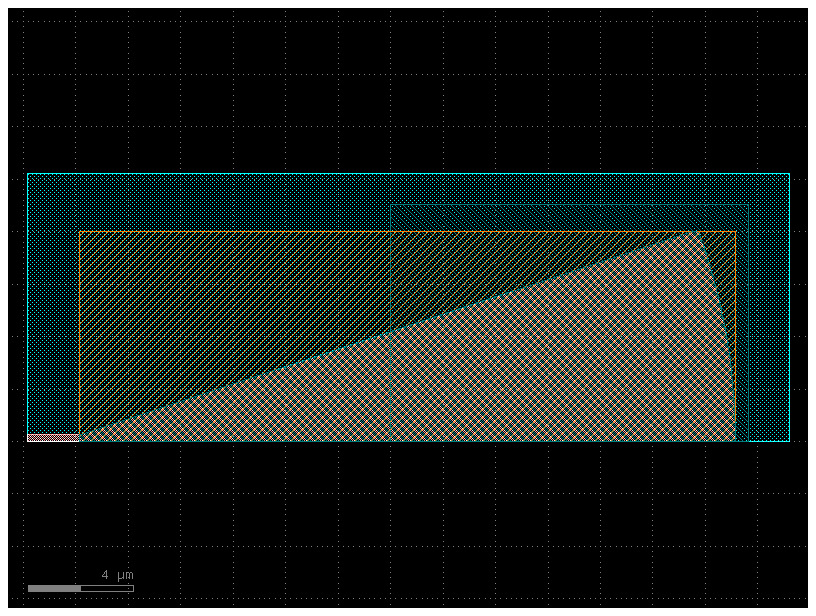

In [2]:
# component to optimize: upper half, mirrored about y=0
# design contour: outline of elliptical grating coupler, grating center at x=0 under beam
gc = gf.components.grating_coupler_elliptical_uniform(
    n_periods=n_periods,
    period=period,
    fill_factor=fill_factor,
    taper_length=taper_length,
    taper_angle=taper_angle,
    wavelength=wl,
    fiber_angle=np.degrees(theta),
    nclad=nox,
    layer_slab=SLAB,
    cross_section=gf.cross_section.cross_section(width=w_wg, layer=WG),
)
q = np.vstack([np.array(p) for ps in gc.get_polygons_points(layers=[WG]).values() for p in ps])
q = q[ConvexHull(q).vertices] - [gc.ports["o2"].x, 0]
p = np.c_[q[:, 0], np.maximum(q[:, 1], 0)]  # upper half
x_design, L, W = p[:, 0].min(), np.ptp(p[:, 0]), 2 * p[:, 1].max()


c = gf.Component()
rect = c << gf.components.rectangle(size=(L, W / 2), layer=DESIGN)
rect.movex(x_design)
# for ps in gc.get_polygons_points(layers=[WG]).values():  # initial design: uniform grating of GC
#     for s in ps:
#         s = np.array(s) - [gc.ports["o2"].x, 0]
#         c.add_polygon(np.c_[s[:, 0], np.maximum(s[:, 1], 0)], layer=WG)
c.add_polygon(p, layer=WG)  # initial design: filled contour

x_wg = x_design - l_wg
c.add_polygon([(x_wg, 0), (x_wg, w_wg / 2), (x_design, w_wg / 2), (x_design, 0)], layer=WG)
c.add_polygon(p, layer=CONTOUR)  # design mask
c.add_polygon(p, layer=SLAB)
for ps in gc.get_polygons_points(layers=[SLAB]).values():  # slab overhang, as in GC
    for s in ps:
        s = np.array(s) - [gc.ports["o2"].x, 0]
        c.add_polygon(np.c_[s[:, 0], np.maximum(s[:, 1], 0)], layer=SLAB)

x_fiber = x_offset + np.sin(theta) * (zmargin + source_offset)
c << gf.components.bbox(  # enclose beam frame, as in GC
    component=c,
    layer=CLAD,
    top=margin,
    right=max(0, x_fiber + R - c.xmax),
)

c.add_port("o1", center=(x_wg, 0), width=w_wg / 2, orientation=180, layer=WG)

c.plot()

In [3]:
frames = [
    lumi.plane_frame(
        "wg",
        start=[-w_wg / 2 - margin, -zmargin],
        stop=[0, h_wg + zmargin],
        boundaries=[("PML", "PEC"), "PML"],
        wls_mode_solver=[wl],
    ),
    lumi.plane_frame(
        "beam",
        modes=[
            [
                lumi.gaussian_mode(
                    D,
                    n_clad,
                    dx=dx,
                    theta=theta,
                    wl=wl,
                    half="y+",
                    Dlim=2 * R,
                )
            ]
        ],
        start=[-R, 0],
        stop=[R, R],
    ),
]

origin = [x_fiber, 0, zmax]  # source above beam monitor, on beam axis
basis = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
sources = [
    lumi.source(
        "o2",
        origin,
        basis,
        wl=wl,
        bandwidth=wl / 8,
        frame="beam",
    )
]

origin = [x_offset + np.sin(theta) * zmargin, 0, z_port]  # beam monitor below source
monitors = [
    lumi.gf_monitor("o1", c, layer_stack, frame="wg"),
    lumi.monitor("o2", origin, basis, frame="beam"),
]

designs = [
    lumi.design(
        name="design",
        lmin=0.15,
        layer=DESIGN,
        contour_layer=CONTOUR,
        fill_material=core,
        void_material=clad,
        component=c,
        layer_stack=layer_stack,
        materials=materials,
        repdims=[3],
        anchordims=[],
    )
]

optimizer = lumi.optimizer(
    stoploss=0.5,
    lowloss=0.7,
    iters=40,
    contrast=.8,
    momentum=0.7,
    init_dA=0.01,
)
targets = [
    lumi.target(src="o2@0-", dst="o1@0+", target=1, weight=1 / nwls, wl=wl)
    for wl in wls
]

tmax =     1.2 / wl * (
        # (zmargin + source_offset + 2 * h_box) / np.cos(theta) * n_clad
        (zmargin + source_offset) / np.cos(theta) * n_clad
        + (L + W / 2 + l_wg) * n_core
    )    + sources[0]["duration"]

bbox = c.bbox_np().tolist()
bbox[0].append(zmin)
bbox[1].append(zmax)

TypeError: optimizer() got an unexpected keyword argument 'iters'

## Solve

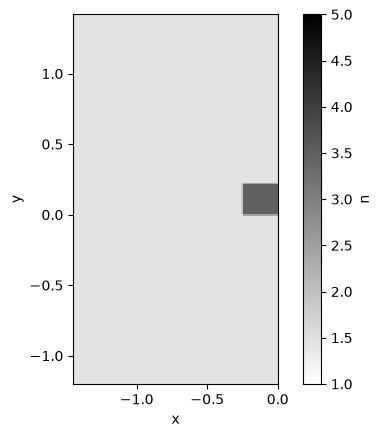

using simulation folder runs/GC_invd


In [ ]:
lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
lumi.setup(
    path=path,
    wl=wl,
    wls=wls,
    frames=frames,
    monitors=monitors,
    sources=sources,
    boundaries=boundaries,
    bbox=bbox,
    materials=materials,
    background=background,
    nres=nres,
    tmax=tmax,
    PML_decay=PML_decay,
    courant=.8,
    subpixel_smoothing=0.5,
    shutoff=shutoff,
    shot_every=shot_every,
    views=views,
    designs=designs,
    targets=targets,
    optimizer=optimizer,
)

In [ ]:
lumi.solve(path)

backend using simulation folder /home/weihu/moon/docs/runs/GC_invd
setting up simulation...
max cell grade per axis: Float32[1.104, 1.101, 1.109]
processing geometry bodies...
generating voxels...
voxelation: 3.079362 seconds (45.33 M allocations: 1.420 GiB, 8.56% gc time, 224.31% compilation time)
Yee mode λ=1.0: neff 2.4602
making sources o2 ...
making monitors o1 o2 ...
making designs design ...
run: /home/weihu/moon/docs/runs/GC_invd
processor: GPU
cpu threads: 48

nres: 10.0
courant: 0.8
subpixel_smoothing: 0.5
  
boundaries: [:PML :PML; :PEC :PML; :PML :PML]

sources
   o2: -0.61, 0, 1.72 

monitors
   o1: -21.84, 0, 0 
   o2: -0.65, 0, 1.42 

original size: (637, 219, 39)
padded size: (696, 234, 73)
cell count: 11,889,072

step size: 60.0 steps/period
source duration: 7.97 periods

max time: 114.22 periods
max steps: 6,853
max load: 74,104,585,776 cell-steps


starting optimization... first iter will be slow due to adjoint compilation.

[1]
contrast: 0.8, momentum: 0.0
saving de

RuntimeError: solver failed (exit code 1)

## Movie

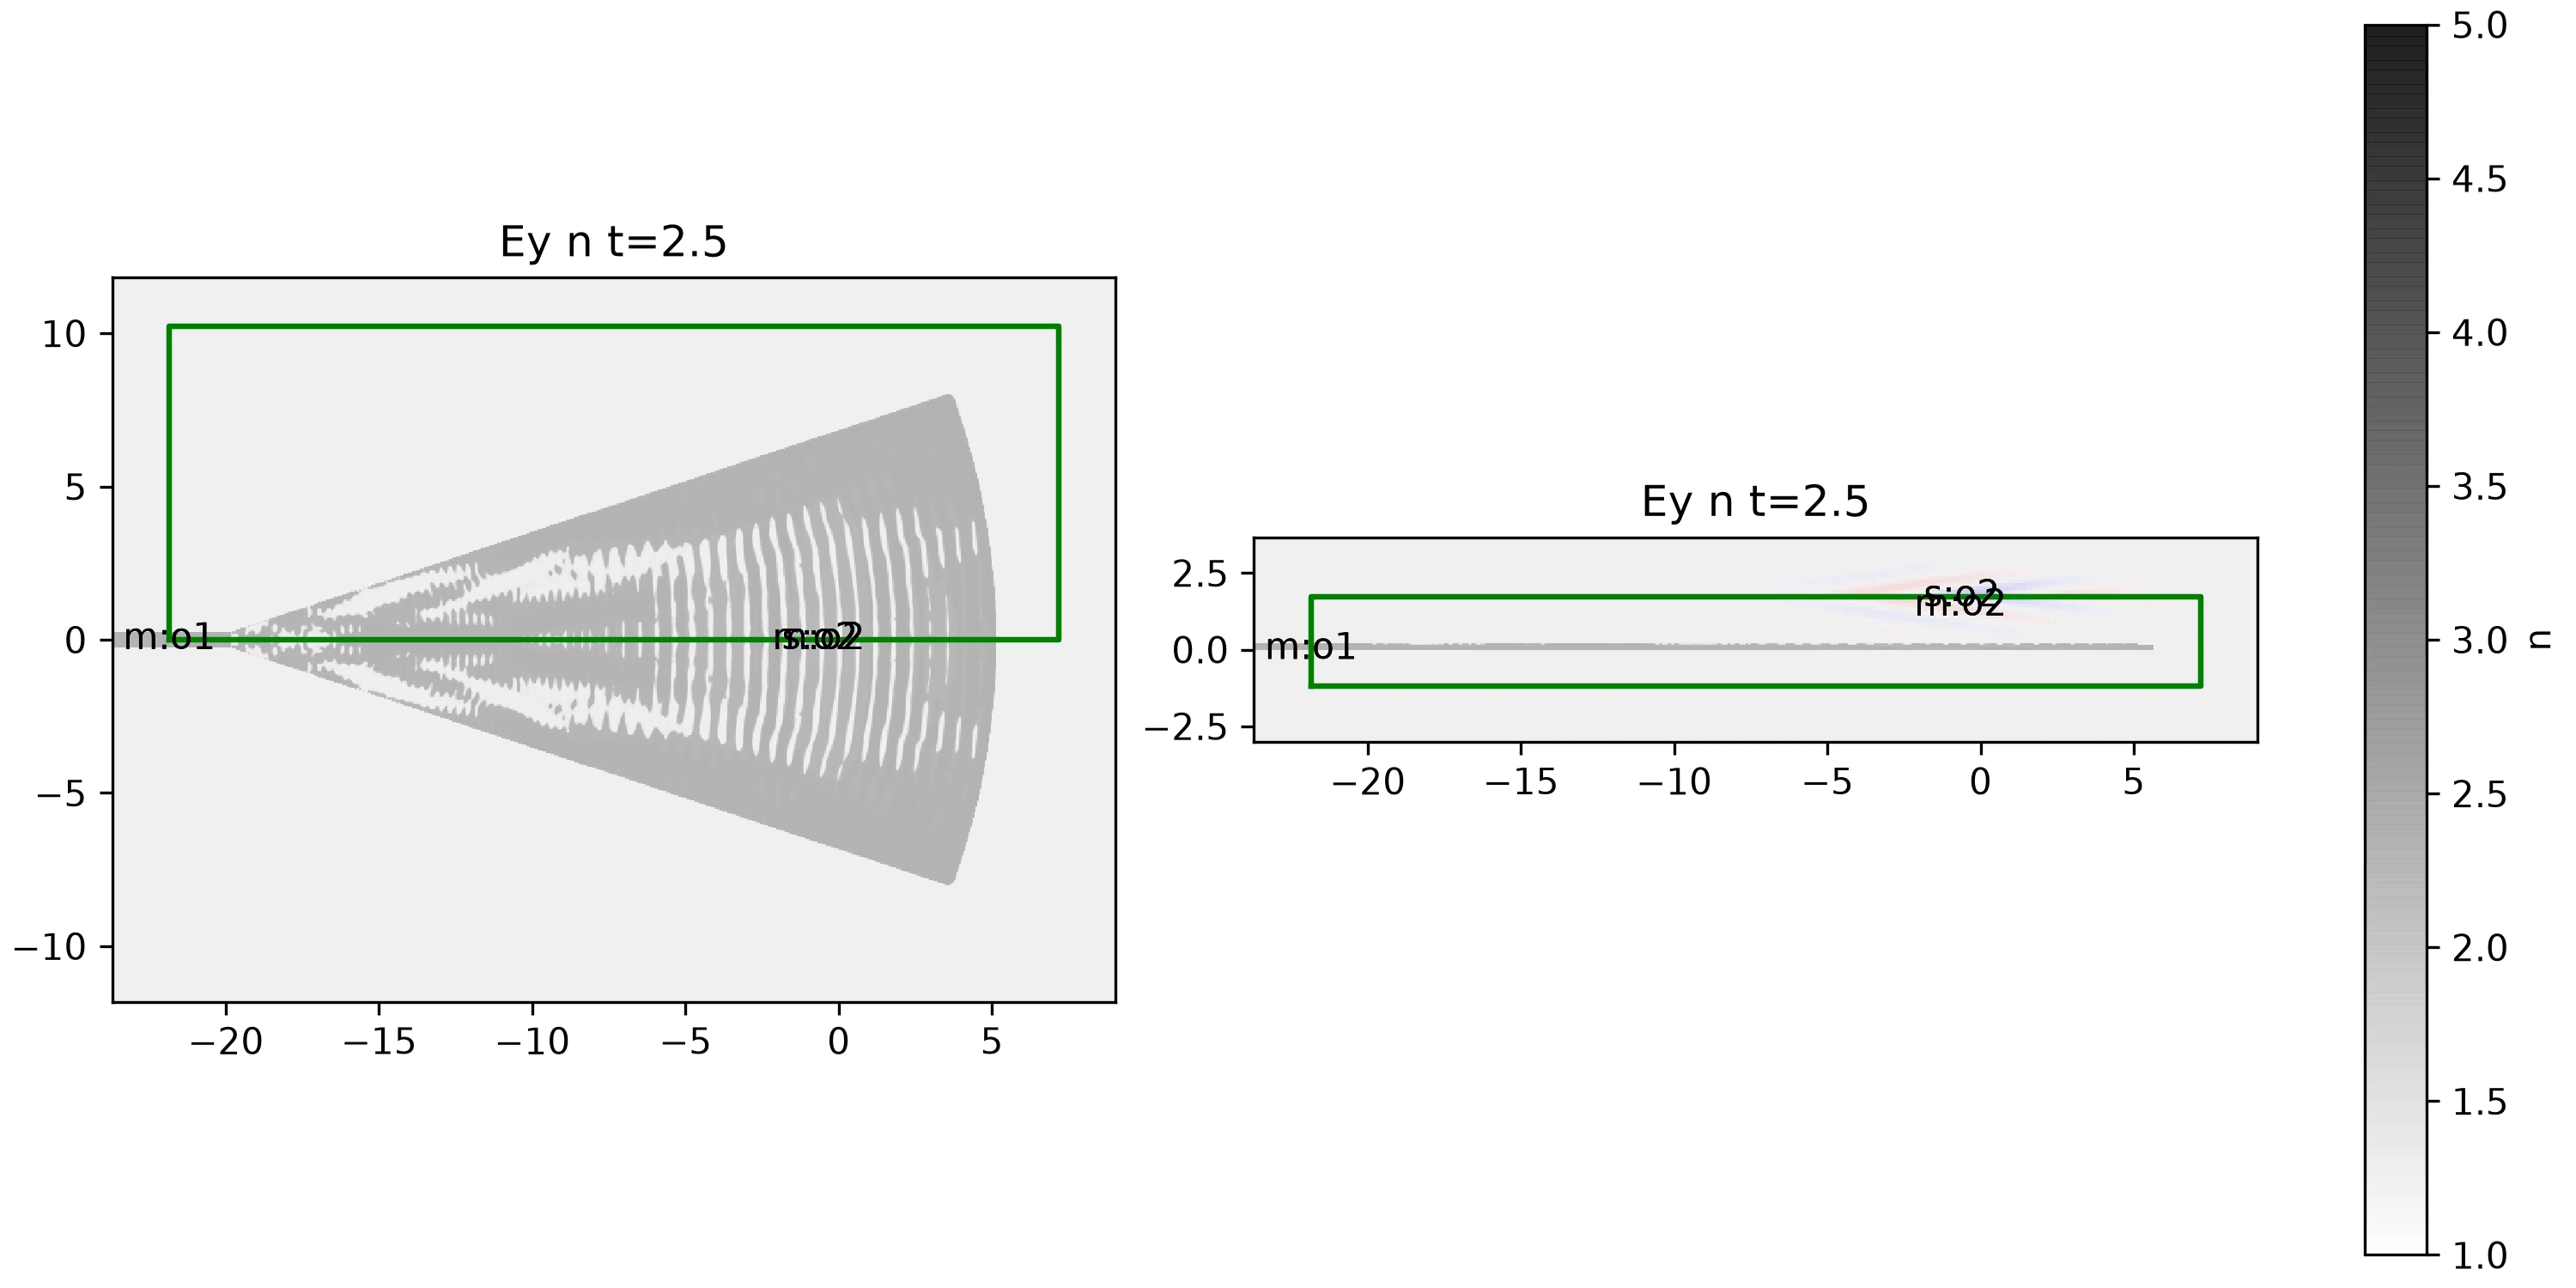

In [ ]:
lumi.movie(path)